# Stage vetting: final direct-death model (`gpd_cens`, `e7a78b19`)

Fit-versus-data plots for the shipped model of the 20260722 v2000 cycle
(`_final3_20260804.json` name `final_gpd_cens_q95_e7a78b19`): S1 logit (wind, SDI, basin,
island, log person-storm-hours), S2 logit (log person-storm-hours only), bulk scaled-logit
(wind, SDI, basin, log person-storm-hours), tail censored GPD (intercept only), q = 0.95.

The final fits are not cached as pickles (the forecast scripts refit on the fly), so this
notebook refits with `refit_model_with_objects` and hands the results to `StagePlotter`
via `register_results`. Draw bands come from `build_draw_models`.

In [10]:
%matplotlib inline
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from idd_figures.lib.io import save_figure
from idd_tc_mortality.refit_with_objects import refit_model_with_objects
from idd_tc_mortality.thresholds import compute_thresholds
from idd_tc_mortality.uncertainty.draw_models import build_draw_models
from idd_tc_mortality.viz.stage_plots import StagePlotter

plt.rcParams['figure.dpi'] = 100
STAGES = ('s1', 's2', 'bulk', 'tail')

In [11]:
ROOT       = Path('/mnt/team/idd/pub/idd_tc_mortality')
MID        = 'e7a78b19e3468d0beb8cb2161dd6d154'          # final_gpd_cens_q95_e7a78b19
DATA_PATH  = ROOT / '00-data'     / '20260722_v2000' / 'input.parquet'
FOLDS_PATH = ROOT / '02-evaluate' / '20260722_v2000_final' / 'fold_assignments.parquet'
PICKS_PATH = ROOT / '02-evaluate' / '20260722_v2000_final' / '_final3_20260804.json'
FOCUS_PATH = ROOT / '03-draws'    / '20260722_v2000' / MID / 'focus_model.json'
FIG_DIR    = ROOT / '05-figures'  / 'working' / f'stage_vetting_{MID[:8]}'   # working slot, overwritten

for p in (DATA_PATH, FOLDS_PATH, PICKS_PATH, FOCUS_PATH):
    assert p.exists(), f'Missing: {p}'
print('All paths resolve.')

All paths resolve.


In [12]:
data  = pd.read_parquet(DATA_PATH)
folds = pd.read_parquet(FOLDS_PATH)
focus = json.loads(FOCUS_PATH.read_text())
pick  = next(p for p in json.loads(PICKS_PATH.read_text()) if p['mid'] == MID)

print(f"{pick['name']}   n={len(data):,} storms   q={focus['threshold_quantile']}")
for s in STAGES:
    print(f"  {s:4s}: {focus[f'{s}_family']:13s} exposure={focus[f'{s}_exposure_mode']:9s} cov={focus[f'{s}_cov']}")

final_gpd_cens_q95_e7a78b19   n=1,903 storms   q=0.95
  s1  : logit         exposure=free      cov={"basin": true, "is_island": true, "sdi": true, "wind_speed": true}
  s2  : logit         exposure=free      cov={"basin": false, "is_island": false, "sdi": false, "wind_speed": false}
  bulk: scaled_logit  exposure=free      cov={"basin": true, "is_island": false, "sdi": true, "wind_speed": true}
  tail: gpd_cens      exposure=excluded  cov={"basin": false, "is_island": false, "sdi": false, "wind_speed": false}


## Refit the four stages (in-sample) and tabulate coefficients

In [13]:
refit = refit_model_with_objects(focus_model=focus, data=data, fold_assignments=folds,
                                 n_seeds=1, n_folds=2)
bad = [s for s in STAGES if refit['is'][s].get('failed')]
assert not bad, f'refit failed: {bad}'

T = float(refit['is']['combined']['threshold_rate'])
death_rate = data['deaths'] / data['exposed']
assert np.isclose(T, compute_thresholds(death_rate.values, np.array([0.95]))[0.95])
print(f'tail threshold rate T = {T:.3e} deaths per person-storm-hour  ({T*1e5:.2f} per 100,000)')

for s in STAGES:
    fit = refit['is'][s]['fit_result']
    tbl = pd.DataFrame({'param': fit.param_names, 'coef': fit.params})
    print(f"\n=== {s}  family={fit.family}  converged={fit.converged}  meta={ {k: v for k, v in fit.meta.items() if k in ('shape_param', 'scale', 'sigma')} }")
    print(tbl[~((tbl['coef'].abs() < 1e-8))].round(4).to_string(index=False))

tail threshold rate T = 3.405e-04 deaths per person-storm-hour  (34.05 per 100,000)

=== s1  family=s1  converged=True  meta={}
      param    coef
      const -2.0731
 wind_speed  0.0364
        sdi -4.9384
   basin_NA  0.2182
   basin_NI -1.3670
   basin_AU -0.9557
   basin_SI -0.4707
   basin_SP -1.0560
   basin_WP -0.2337
  is_island  0.1384
log_exposed  0.2531

=== s2  family=logit  converged=True  meta={}
      param    coef
      const  8.7388
log_exposed -0.8727

=== bulk  family=scaled_logit  converged=True  meta={}
      param    coef
      const  9.8411
 wind_speed  0.0148
        sdi -3.7788
   basin_NA  0.1375
   basin_NI  0.6362
   basin_AU -0.6745
   basin_SI -0.4593
   basin_SP -0.1821
   basin_WP  0.5496
log_exposed -0.8634

=== tail  family=gpd  converged=True  meta={'shape_param': 0.8218729164494737}
param    coef
const -6.6117


## Coefficient draws (parameter uncertainty bands) and the plotter

In [14]:
N_DRAWS = 200
draws = build_draw_models(refit, focus, data, n_draws=N_DRAWS, draw_coefs=True, draw_scale=True, seed=42)

plotter = StagePlotter(data=data, results_dir=FOCUS_PATH.parent)   # results_dir unused after register
plotter.register_results(focus, {s: refit['is'][s]['fit_result'] for s in STAGES})
print(f'{len(draws)} draw models; tail xi across draws: '
      f'{np.mean([d.tail.scale for d in draws]):.3f} ± {np.std([d.tail.scale for d in draws]):.3f}')

200 draw models; tail xi across draws: 0.833 ± 0.312


## Stages 1-3, default 3x3 vets

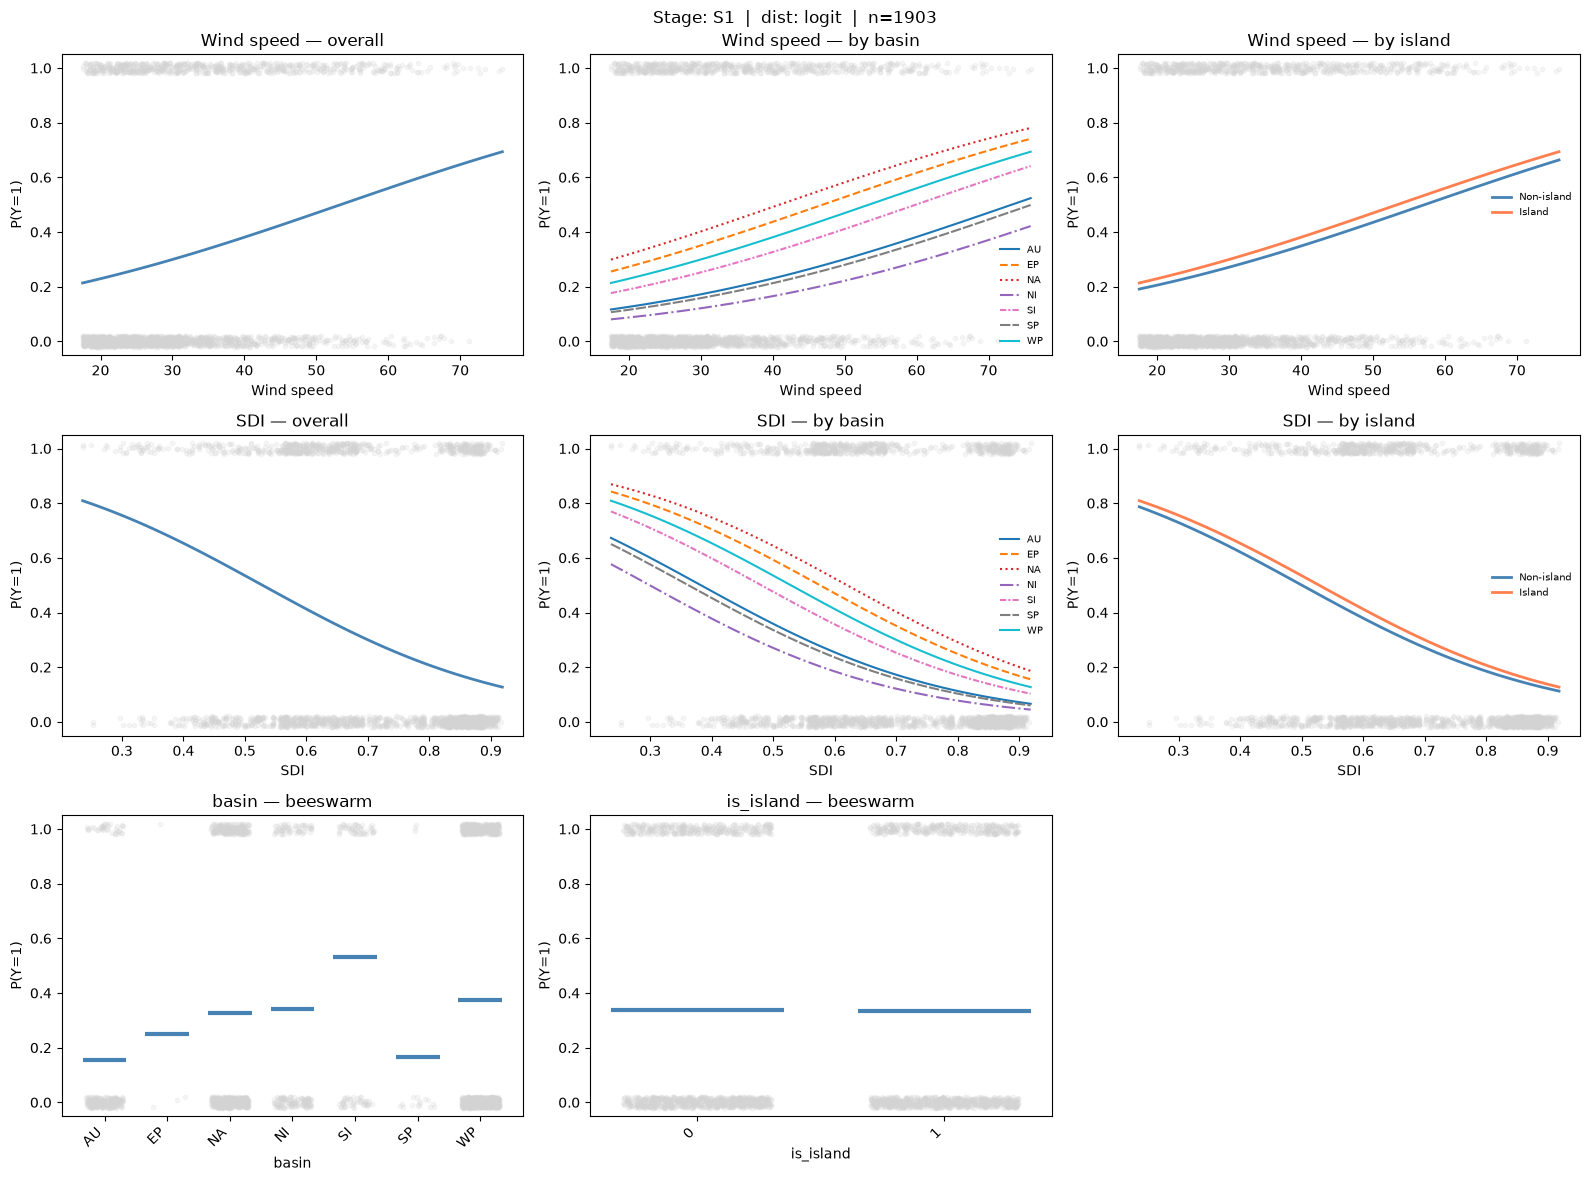

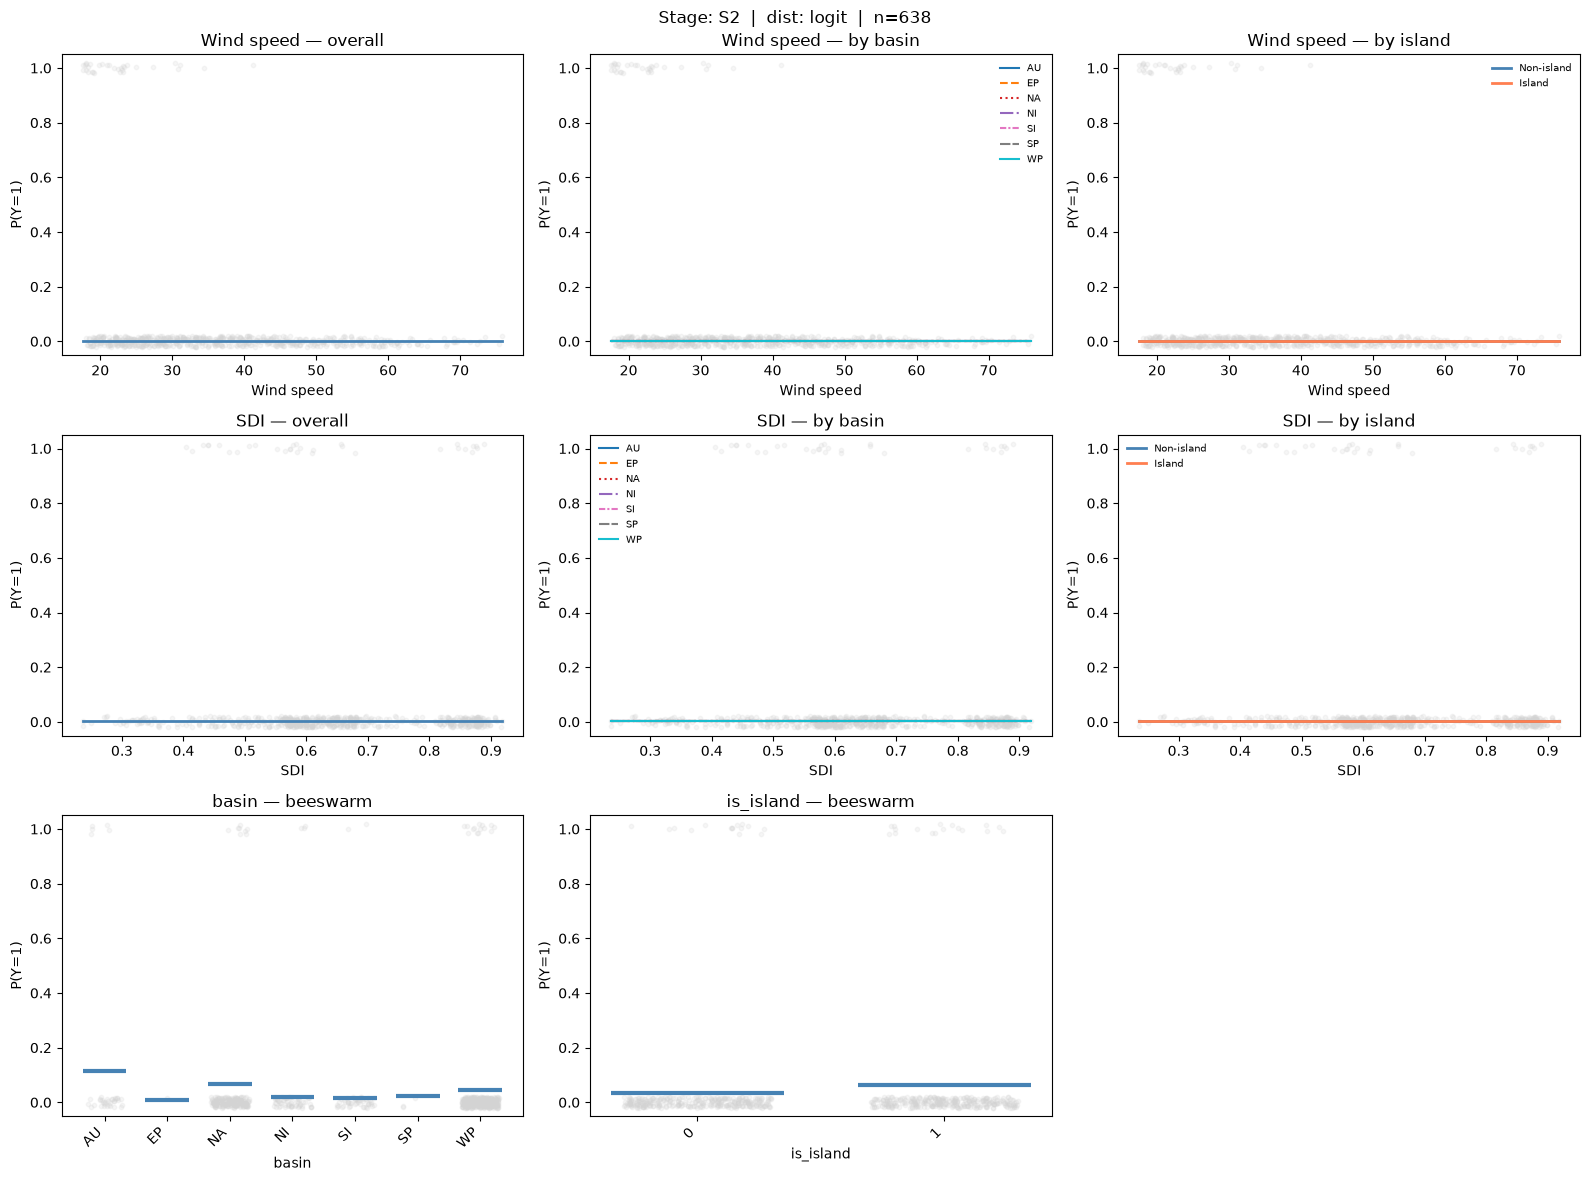

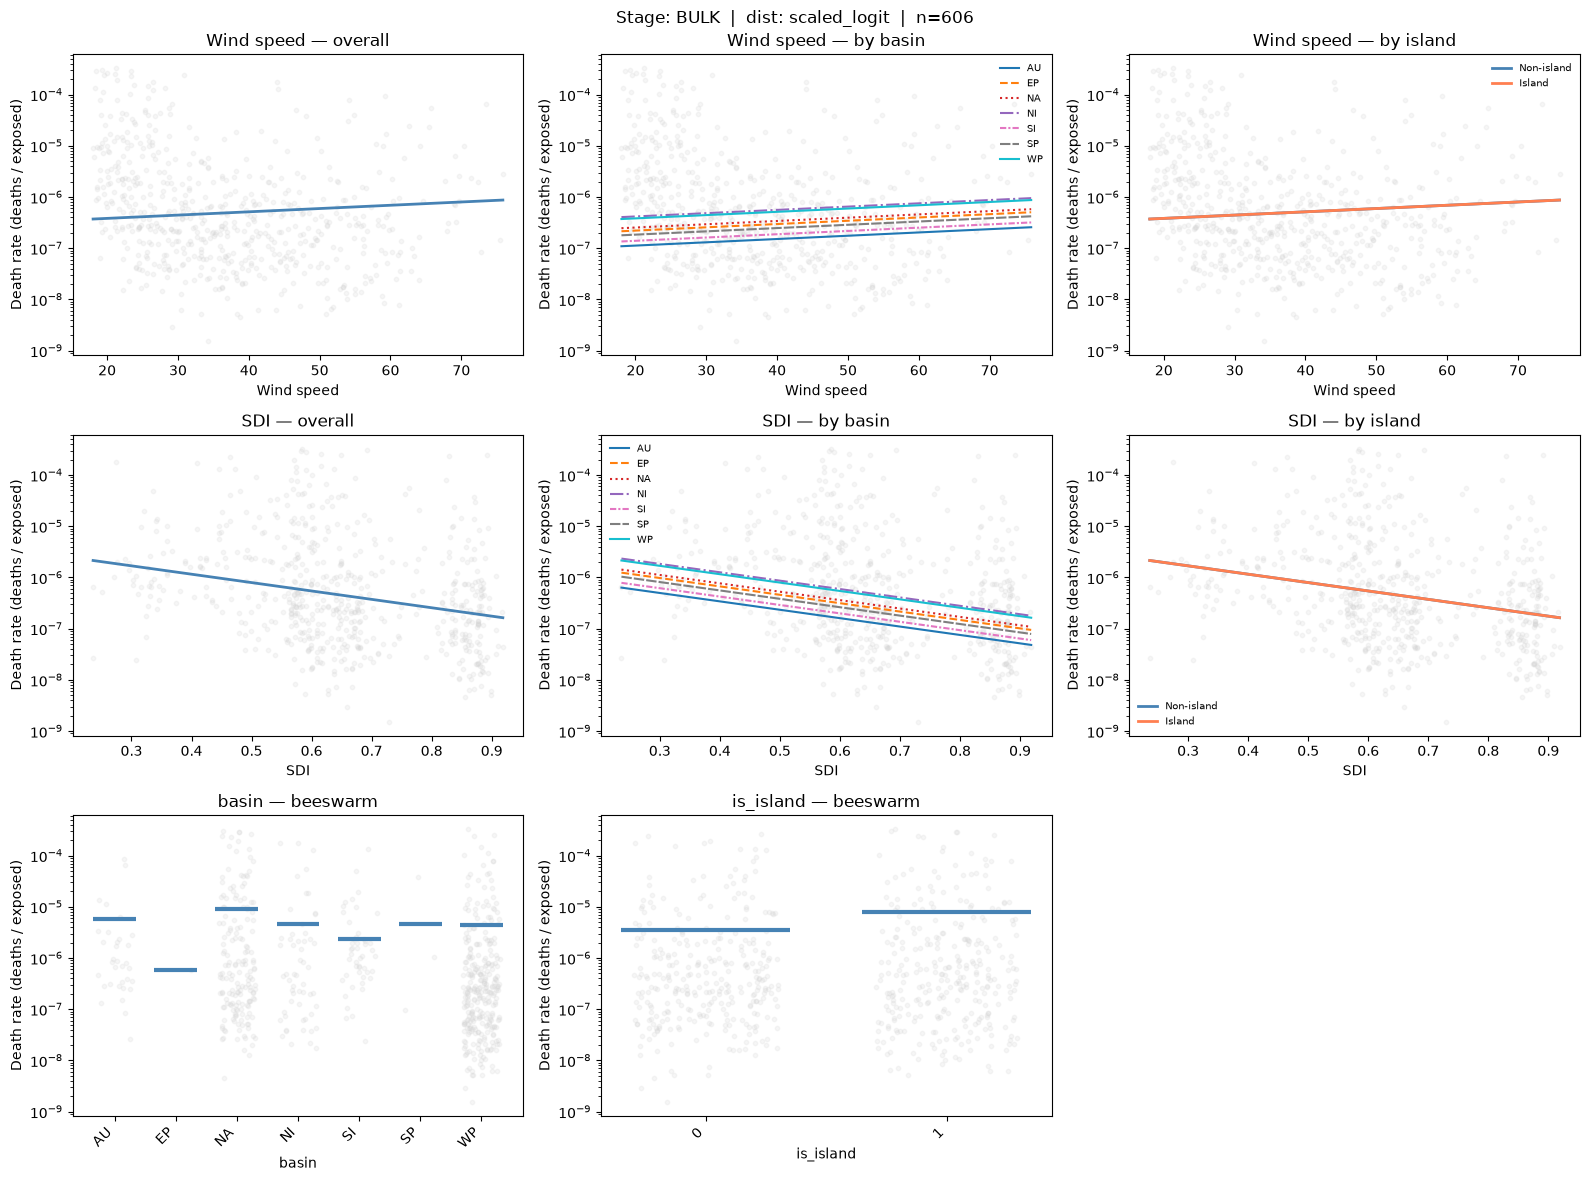

In [15]:
for s in ('s1', 's2', 'bulk'):
    fig = plotter.vet_stage(focus, stage=s, draws=draws)
    save_figure(fig, FIG_DIR / f'{s}_default.png', dpi=120)
    plt.show()

## Stages 1-2: by-basin two-panel figures (wind speed, SDI)

Same layout as the 2026-05 vetting figures. Note the final S2 has no covariates besides
people-storm-hours, so its by-basin curves coincide and are flat in wind speed and SDI.

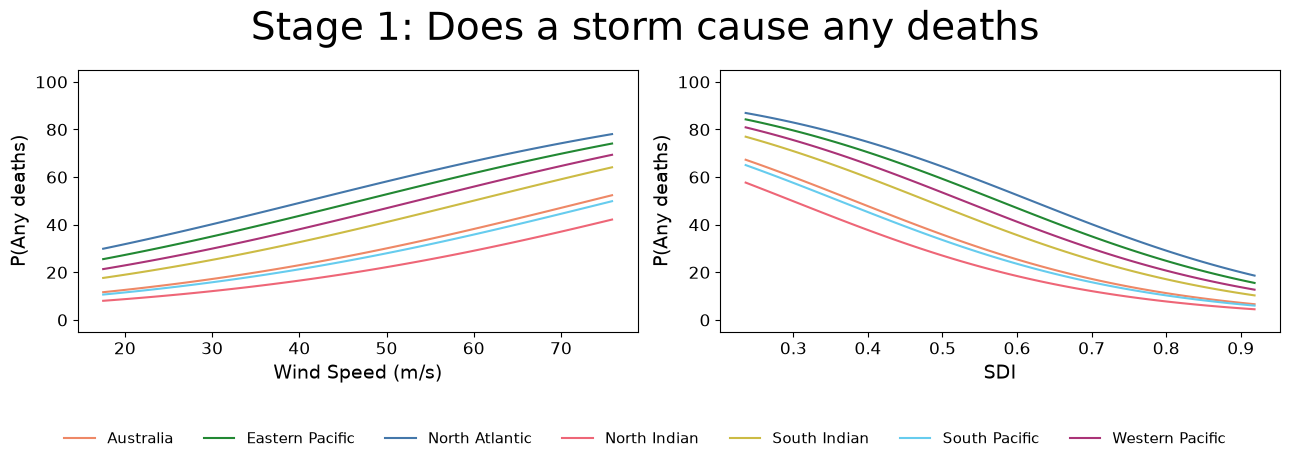

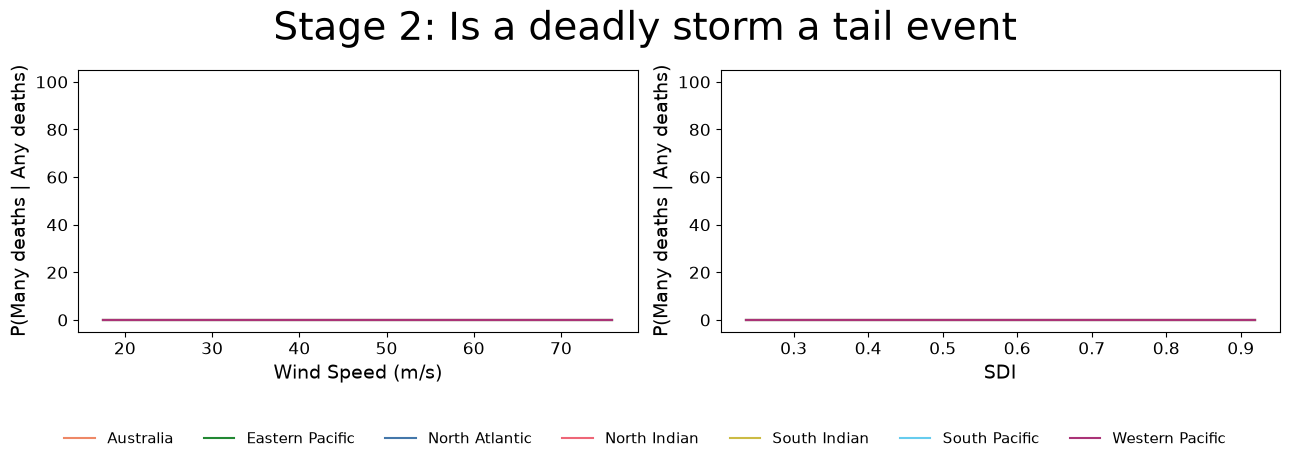

In [16]:
BASIN_COLORS = {'NA': '#4477AA', 'NI': '#EE6677', 'EP': '#228833', 'SI': '#CCBB44',
                'SP': '#66CCEE', 'WP': '#AA3377', 'AU': '#EE8866'}   # 7 basins in the 20260722 data
BASIN_NAMES  = {'NA': 'North Atlantic', 'NI': 'North Indian', 'EP': 'Eastern Pacific', 'SI': 'South Indian',
                'SP': 'South Pacific', 'WP': 'Western Pacific', 'AU': 'Australia'}


def by_basin_config(suptitle, y_label, uncertainty=True):
    unc = {'show': uncertainty, 'percentiles': (5, 95), 'alpha': 0.5, 'color': None}
    panel = {'kind': 'cont_by_basin', 'row': 0, 'y_label': y_label, 'y_scale': 100,
             'title': None, 'uncertainty': unc}
    return {
      'layout': {'figsize': (13, 4.6), 'suptitle': suptitle, 'tight_layout': True,
                 'panels': {'wind_basin': {**panel, 'col': 0, 'x_col': 'wind_speed', 'x_label': 'Wind Speed (m/s)'},
                            'sdi_basin':  {**panel, 'col': 1, 'x_col': 'sdi',        'x_label': 'SDI'}}},
      'style': {'scatter_obs': {'show': False},
                'basin': {b: {'color': BASIN_COLORS[b], 'ls': '-', 'label': BASIN_NAMES[b]} for b in BASIN_COLORS},
                'fonts': {'suptitle': 28, 'panel_title': 14, 'axis_label': 14, 'tick': 12, 'legend': 11}},
      # pad = bottom margin (figure fraction); anchor at the canvas bottom so the legend survives a non-tight save
      'legend': {'mode': 'shared_below', 'ncol': 7, 'pad': 0.28, 'bbox_to_anchor': (0.5, 0.0)},
    }


fig = plotter.vet_stage(focus, stage='s1', draws=draws,
                        config=by_basin_config('Stage 1: Does a storm cause any deaths', 'P(Any deaths)'))
save_figure(fig, FIG_DIR / 's1_by_basin.png', dpi=120)
plt.show()

fig = plotter.vet_stage(focus, stage='s2', draws=draws,
                        config=by_basin_config('Stage 2: Is a deadly storm a tail event', 'P(Many deaths | Any deaths)'))
save_figure(fig, FIG_DIR / 's2_by_basin.png', dpi=120)
plt.show()

## Stage 3: bulk density overlay (wind categories x SDI quintiles, exposure at its median)

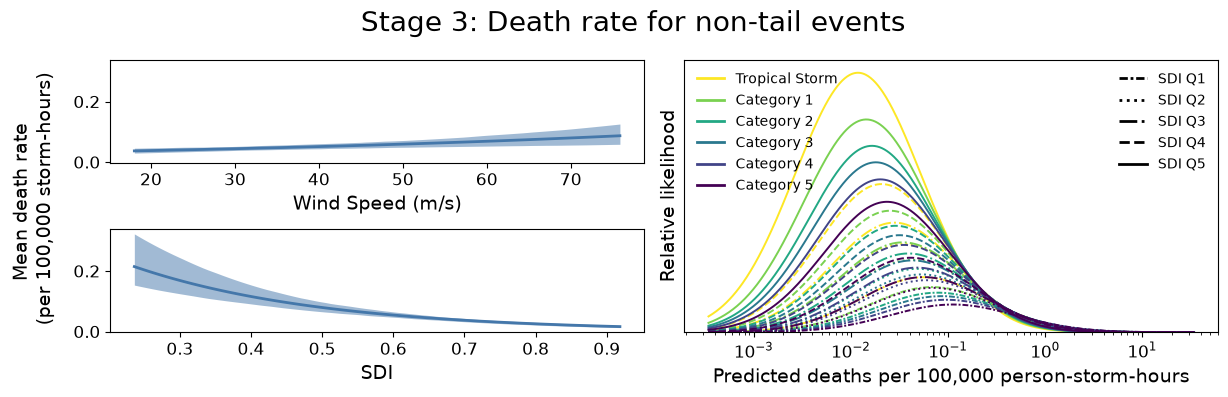

In [17]:
bulk_config = {
  'layout': {
    'figsize': (12, 4), 'suptitle': 'Stage 3: Death rate for non-tail events', 'tight_layout': True,
    'panels': {
      'wind_overall': {'kind': 'cont_overall', 'x_col': 'wind_speed', 'row': 0, 'col': 0,
                       'x_label': 'Wind Speed (m/s)', 'y_label': 'Mean death rate (per 100,000 storm hours)',
                       'y_scale': 100000, 'title': None,
                       'uncertainty': {'show': True, 'percentiles': (5, 95), 'alpha': 0.5, 'color': None}},
      'sdi_overall':  {'kind': 'cont_overall', 'x_col': 'sdi', 'row': 1, 'col': 0,
                       'x_label': 'SDI', 'y_label': 'Mean death rate (per 100,000 storm hours)',
                       'y_scale': 100000, 'title': None,
                       'uncertainty': {'show': True, 'percentiles': (5, 95), 'alpha': 0.5, 'color': None}},
      'pdf_overlay':  {'kind': 'cont_pdf_quintile', 'row': 0, 'col': 1, 'rowspan': 2,
                       'color_cmap': 'viridis_r', 'color_col': 'wind_speed',
                       'color_values': [18, 33, 43, 50, 58, 70],
                       'color_labels': ['Tropical Storm', 'Category 1', 'Category 2', 'Category 3', 'Category 4', 'Category 5'],
                       'style_col': 'sdi', 'style_legend_label': 'SDI',
                       'fixed_col': 'exposed', 'fixed_quantile': 0.5,
                       'r_grid_lo': 1e-5, 'r_grid_hi': 1 - 1e-5,
                       'x_label': 'Predicted deaths per 100,000 person-storm-hours',
                       'y_label': 'Relative likelihood', 'xscale': 'log'},
    },
  },
  'style': {'scatter_obs': {'show': False}, 'pred_line': {'color': '#4477AA', 'lw': 2, 'ls': '-'},
            'fonts': {'suptitle': 20, 'panel_title': 14, 'axis_label': 14, 'tick': 12, 'legend': 12}},
  'axes': {'y_scale_mode': 'linear', 'scientific_notation': False,
           'share_y': ['wind_overall', 'sdi_overall'], 'include_zero_y': True},
  'legend': {'mode': 'none'},
}
fig = plotter.vet_stage(focus, stage='bulk', config=bulk_config, draws=draws)
fig.axes[0].set_ylabel(''); fig.axes[1].set_ylabel('')
fig.text(0.00, 0.5, 'Mean death rate\n (per 100,000 storm-hours)', rotation=90, va='center', ha='center', fontsize=14)
save_figure(fig, FIG_DIR / 'bulk_pdf_overlay.png', dpi=120)
plt.show()

## Stage 4: censored-GPD tail density (linear and log x)

Interior GPD density of the excess rate above T, at the intercept-only fit (`sigma = exp(const)`,
`xi = shape_param`); the band is the 5-95% envelope over the coefficient draws. Censoring at each
storm's physical cap is predict-only and does not change this interior shape.

In [20]:
FIG_DIR

PosixPath('/mnt/team/idd/pub/idd_tc_mortality/05-figures/working/stage_vetting_e7a78b19')

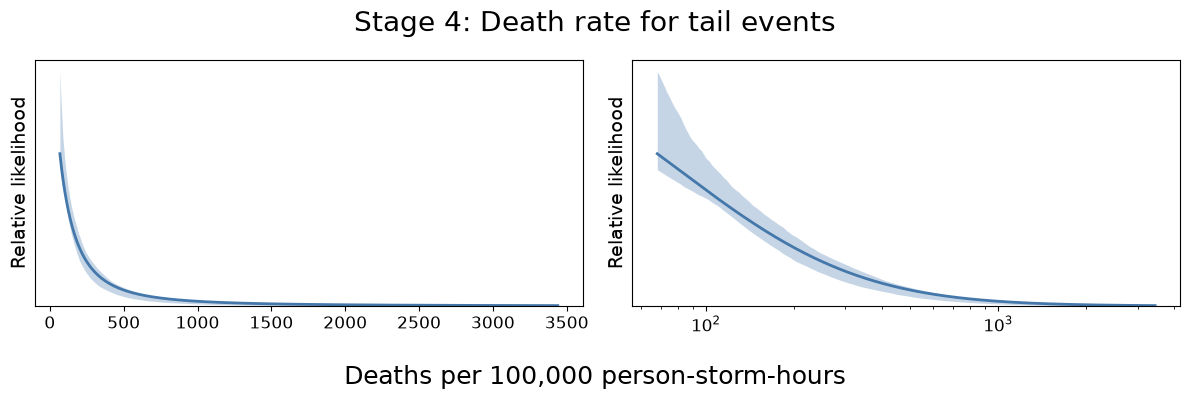

In [18]:
tail_pdf = {
    'kind': 'cont_pdf_quintile', 'row': 0, 'r_grid_lo': 1, 'r_grid_hi': 100,
    'x_label': '', 'y_label': 'Relative likelihood', 'hide_y_ticks': True, 'inline_legends': False,
    'uncertainty': {'show': True, 'percentiles': (5, 95), 'alpha': 0.3},
}
tail_config = {
  'layout': {'figsize': (12, 4), 'suptitle': 'Stage 4: Death rate for tail events', 'tight_layout': True,
             'panels': {'pdf_linear': {**tail_pdf, 'col': 0, 'xscale': 'linear'},
                        'pdf_log':    {**tail_pdf, 'col': 1, 'xscale': 'log'}}},
  'style': {'scatter_obs': {'show': False}, 'pred_line': {'color': '#4477AA', 'lw': 2, 'ls': '-'},
            'fonts': {'suptitle': 20, 'panel_title': 14, 'axis_label': 14, 'tick': 12}},
  'axes': {'y_scale_mode': 'linear', 'include_zero_y': True},
  'legend': {'mode': 'none'},
}
fig = plotter.vet_stage(focus, stage='tail', config=tail_config, draws=draws)
fig.subplots_adjust(bottom=0.24)   # room for the shared x label inside the canvas (save is not bbox-tight)
fig.text(0.5, 0.03, 'Deaths per 100,000 person-storm-hours', ha='center', va='bottom', fontsize=18)
save_figure(fig, FIG_DIR / 'tail_pdf.png', dpi=120)
plt.show()

## Stage 4: default 3x3 vet (predictions go through the cap-aware censored mean)

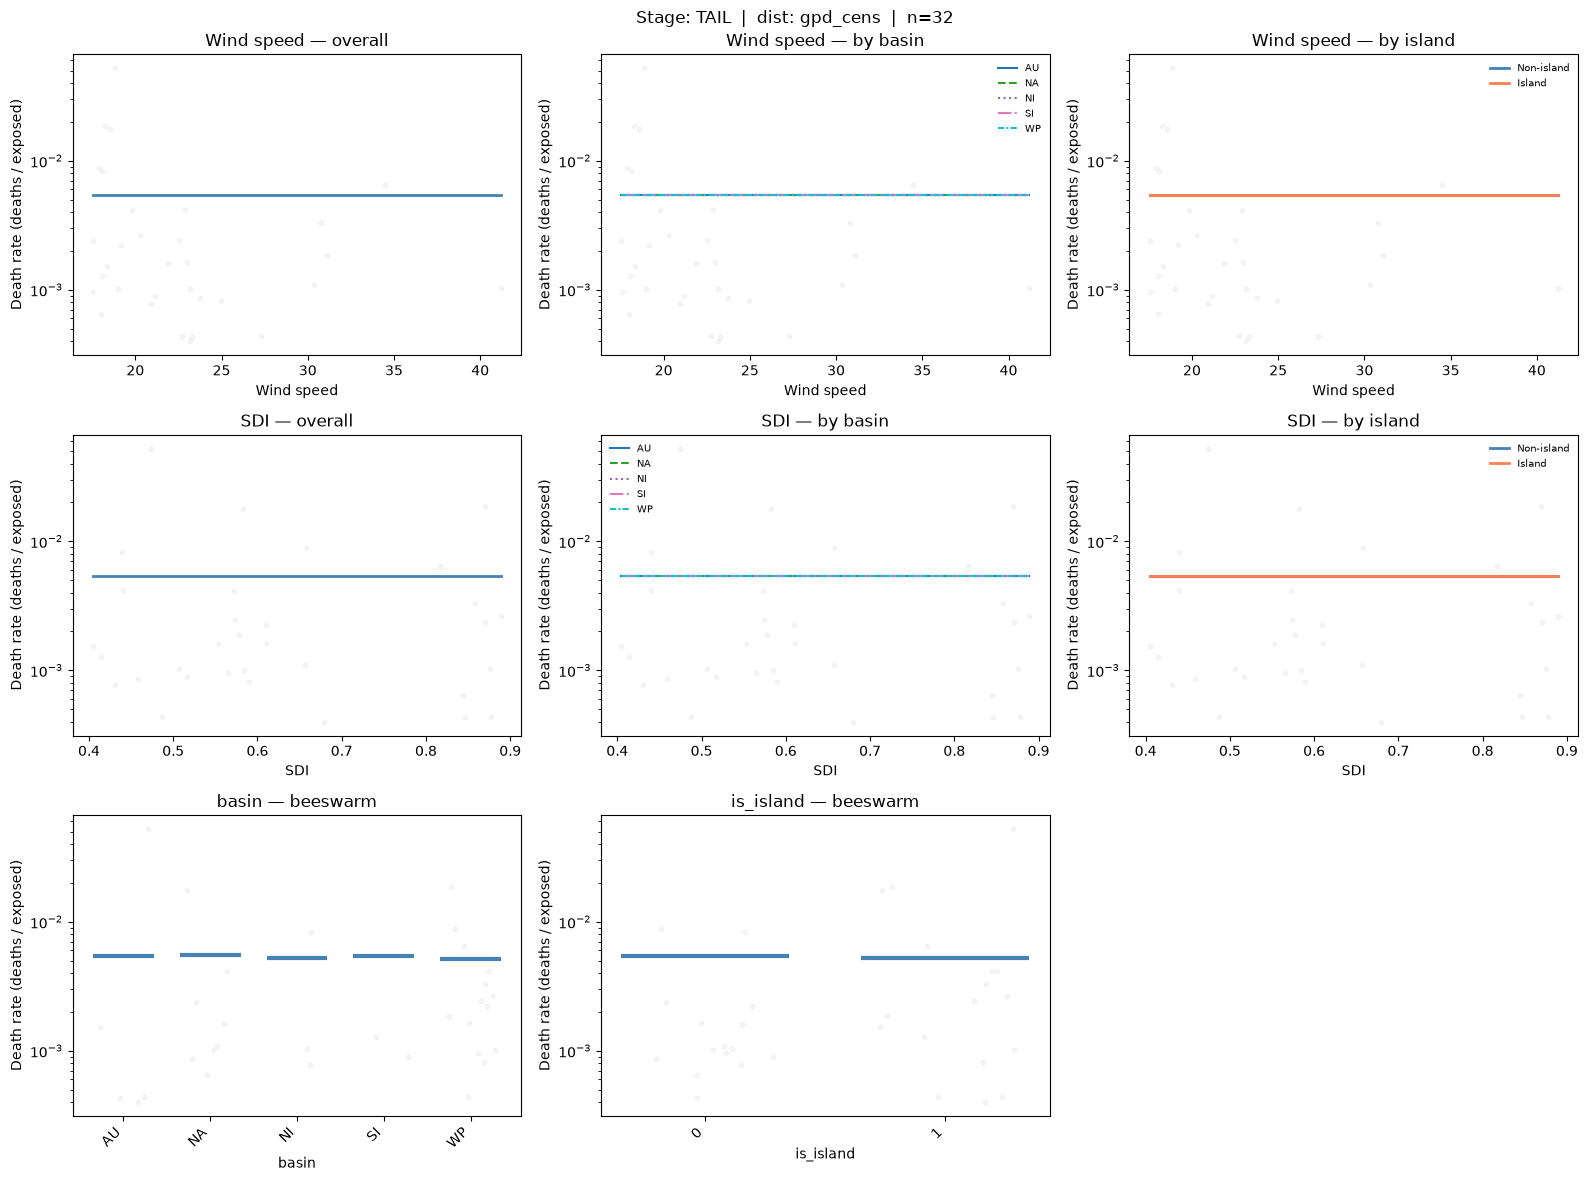

In [19]:
fig = plotter.vet_stage(focus, stage='tail', draws=draws)
save_figure(fig, FIG_DIR / 'tail_default.png', dpi=120)
plt.show()